In [1]:
import site
import sys
import subprocess
import os

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
if os.path.exists(user_site):
    site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print('¡PyLTSpice ya estaba instalado y listo para usar!')
except ImportError:
    print('PyLTSpice no fue encontrado. Instalando automáticamente...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--user', 'PyLTSpice'])
    if os.path.exists(user_site):
        site.addsitedir(user_site)
    from PyLTSpice import RawRead
    print('¡PyLTSpice se instaló e importó correctamente!')

¡PyLTSpice ya estaba instalado y listo para usar!


In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import scipy.stats as stats
import os

# ==============================================================================
# 1. CARGAR Y EXTRAER LOS DATOS DEL SELF-BIAS (A PRUEBA DE FALLOS)
# ==============================================================================
ruta_archivo = "/headless/.xschem/simulations/self_bias_mc.txt"

if not os.path.exists(ruta_archivo):
    print(f"⚠️ Archivo no encontrado en: {ruta_archivo}")
else:
    with open(ruta_archivo, 'r') as f:
        texto = f.read()

    # Regex estricto que solo atrapa números reales en la misma línea
    def extraer(variable, texto):
        patron = rf"{variable}[ \t]*=[ \t]*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"
        encontrados = re.findall(patron, texto)
        valores = []
        for x in encontrados:
            try:
                valores.append(float(x))
            except ValueError:
                pass
        return valores

    # Diccionario con todos los parámetros del Self-Bias
    candidatos = {
        'Ibias OP (uA)': extraer('ibias_op_uA', texto),
        'Ibias P1 (uA)': extraer('ibias_p1_uA', texto),
        'Vgp P1 (V)': extraer('vgp_p1', texto),
        'Vsgp P1 (V)': extraer('vsgp_p1', texto),
        'VDI P1 (V)': extraer('vdi_p1', texto),
        'VR P1 (V)': extraer('vr_p1', texto),
        'Ibias P2 (uA)': extraer('ibias_p2_uA', texto),
        'Vgp P2 (V)': extraer('vgp_p2', texto),
        'Vsgp P2 (V)': extraer('vsgp_p2', texto),
        'VDI P2 (V)': extraer('vdi_p2', texto),
        'VR P2 (V)': extraer('vr_p2', texto),
        'Vgp Final (V)': extraer('vgp_final', texto),
        'Vsgp Final (V)': extraer('vsgp_final', texto),
        'VDI Final (V)': extraer('vdi_final', texto),
        'VR Final (V)': extraer('vr_final', texto),
    }

    # Filtramos solo las variables que tengan datos válidos
    datos_extraidos = {k: v for k, v in candidatos.items() if len(v) > 0}

    # Calculamos Ibias a partir de VR (~14.5 kOhm) si no se midió directo
    if 'VR P1 (V)' in datos_extraidos and 'Ibias P1 (uA)' not in datos_extraidos:
        datos_extraidos['Ibias Calc P1 (uA)'] = [(vr / 14500.0) * 1e6 for vr in datos_extraidos['VR P1 (V)']]
    if 'VR P2 (V)' in datos_extraidos and 'Ibias P2 (uA)' not in datos_extraidos:
        datos_extraidos['Ibias Calc P2 (uA)'] = [(vr / 14500.0) * 1e6 for vr in datos_extraidos['VR P2 (V)']]

    # Creamos el DataFrame
    df_mc = pd.DataFrame.from_dict(datos_extraidos, orient='index').T

    print(f"✅ Muestras extraídas por variable:\n{df_mc.count()}\n")
    display(df_mc.head(10))
    display(df_mc.describe().loc[['count', 'mean', 'std', 'min', 'max']])

✅ Muestras extraídas por variable:
Vgp P1 (V)            92
Vsgp P1 (V)           92
VDI P1 (V)            92
VR P1 (V)             92
Vgp P2 (V)            92
Vsgp P2 (V)           92
VDI P2 (V)            92
VR P2 (V)             92
Ibias Calc P1 (uA)    92
Ibias Calc P2 (uA)    92
dtype: int64



,Vgp P1 (V),Vsgp P1 (V),VDI P1 (V),VR P1 (V),Vgp P2 (V),Vsgp P2 (V),VDI P2 (V),VR P2 (V),Ibias Calc P1 (uA),Ibias Calc P2 (uA)
0,1.19866,0.601339,1.45327,0.705318,1.19866,0.601338,1.45327,0.705317,48.642621,48.642552
1,1.19758,0.602419,1.45193,0.704067,1.19758,0.602419,1.45193,0.704067,48.556345,48.556345
2,1.19687,0.603125,1.45189,0.702974,1.19687,0.603125,1.45189,0.702974,48.480966,48.480966
3,1.19459,0.605409,1.45747,0.705330,1.19459,0.605409,1.45747,0.705330,48.643448,48.643448
4,1.20302,0.596984,1.43798,0.692787,1.20302,0.596984,1.43798,0.692787,47.778414,47.778414
5,1.19543,0.604571,1.45635,0.706157,1.19543,0.604571,1.45635,0.706157,48.700483,48.700483
6,1.19340,0.606596,1.45797,0.707889,1.19340,0.606596,1.45797,0.707889,48.819931,48.819931
7,1.19789,0.602114,1.45110,0.701282,1.19789,0.602114,1.45110,0.701282,48.364276,48.364276
8,1.19809,0.601912,1.45292,0.704637,1.19809,0.601914,1.45292,0.704638,48.595655,48.595724
9,1.19739,0.602610,1.44877,0.701935,1.19739,0.602610,1.44877,0.701935,48.409310,48.409310


,Vgp P1 (V),Vsgp P1 (V),VDI P1 (V),VR P1 (V),Vgp P2 (V),Vsgp P2 (V),VDI P2 (V),VR P2 (V),Ibias Calc P1 (uA),Ibias Calc P2 (uA)
count,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000
mean,1.200672,0.599328,1.446528,0.698880,1.200668,0.599332,1.446534,0.698883,48.198642,48.198841
std,0.003321,0.003321,0.005884,0.004419,0.003325,0.003325,0.005887,0.004420,0.304739,0.304822
min,1.193400,0.589940,1.432710,0.687819,1.193400,0.589940,1.432710,0.687819,47.435793,47.435793
max,1.210060,0.606596,1.459810,0.708200,1.210060,0.606596,1.459810,0.708201,48.841379,48.841448


<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_7050/2614295503.py:27: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(x, p, 'k', linewidth=2, label=f'Distribución Normal ($\sigma/\mu$ = {cv:.2f}%)')
/tmp/ipykernel_7050/2614295503.py:30: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=f'Media ($\mu$): {mu:.4f}')
/tmp/ipykernel_7050/2614295503.py:31: SyntaxWarning: invalid escape sequence '\s'
  plt.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'-3$\sigma$: {mu-3*sigma:.4f}')
/tmp/ipykernel_7050/2614295503.py:32:

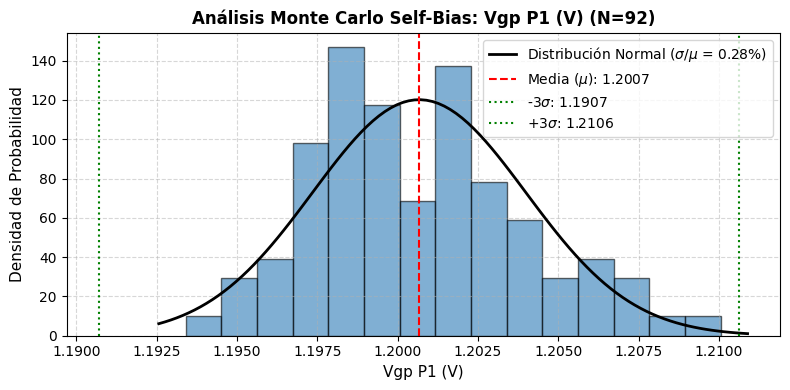

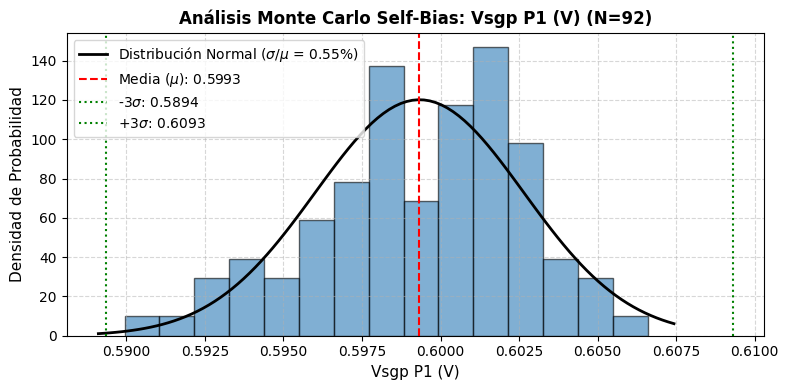

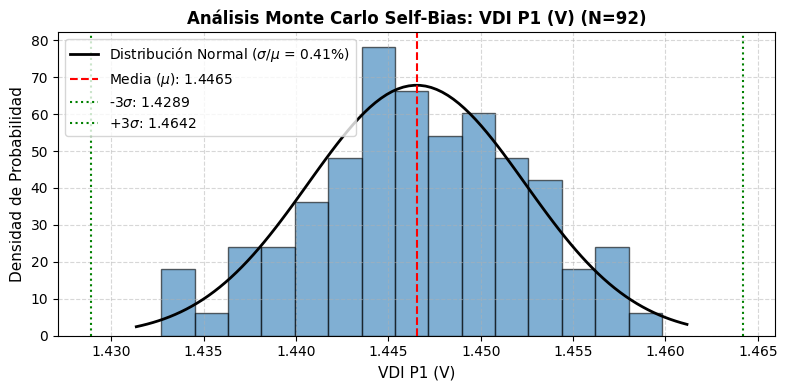

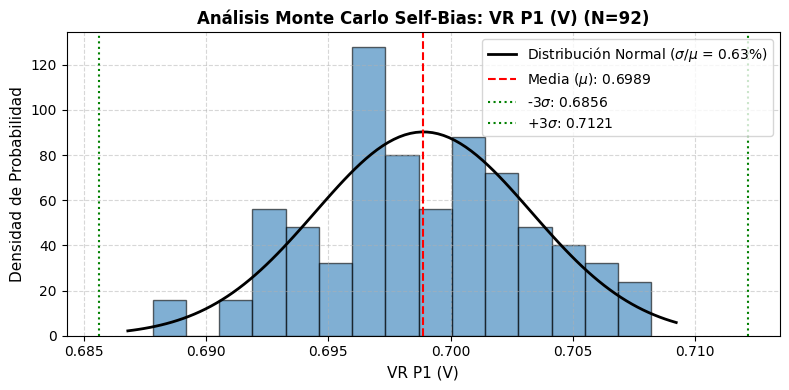

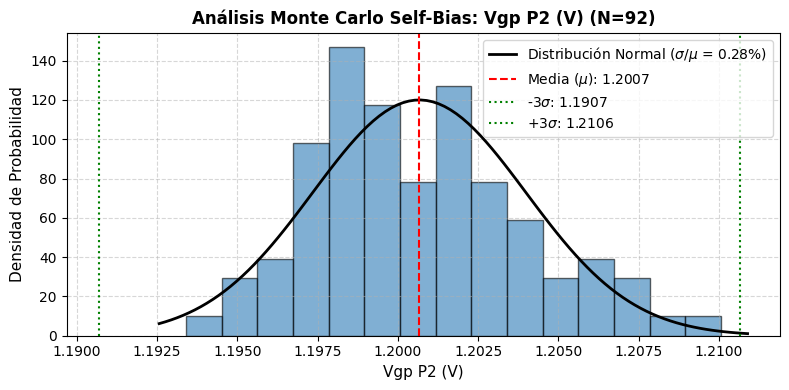

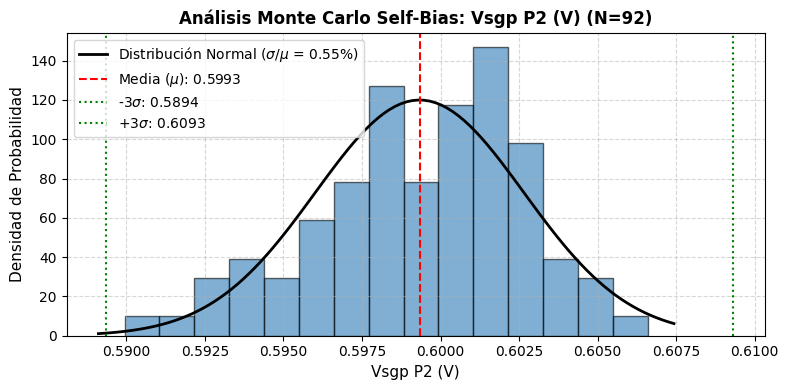

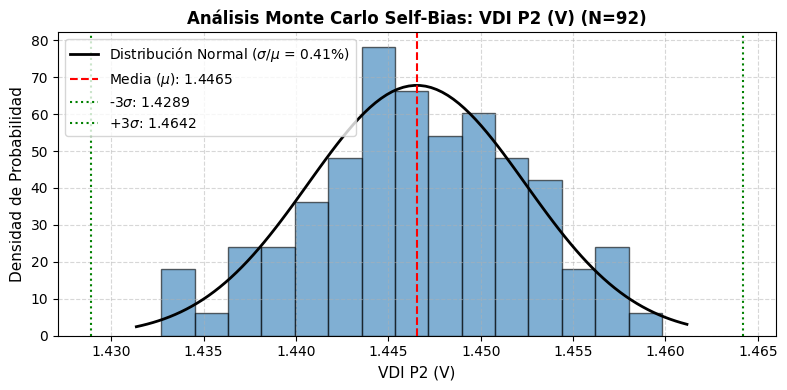

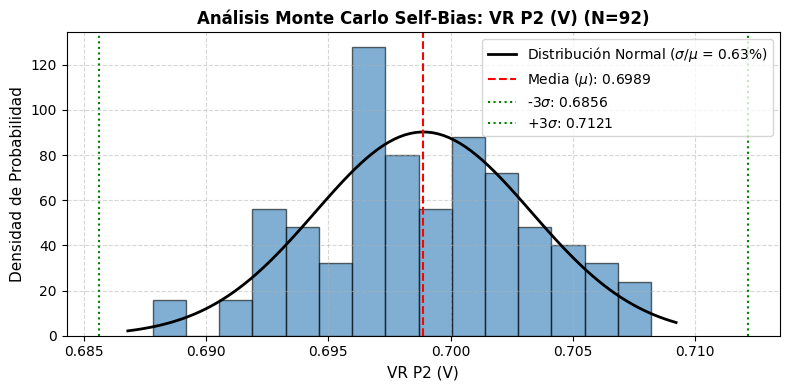

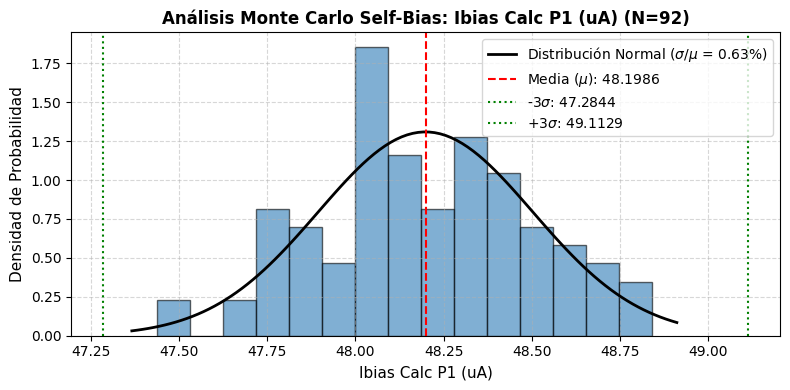

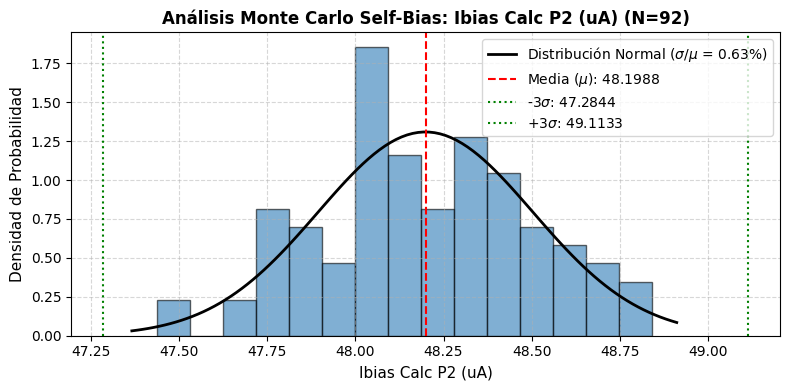

In [3]:
# ==============================================================================
# 2. FUNCIÓN PARA GRAFICAR HISTOGRAMAS Y CAMPANA DE GAUSS
# ==============================================================================
def graficar_gauss(df, columna):
    # Quitamos datos nulos por si alguna simulación falló
    datos = df[columna].dropna()
    if len(datos) < 2:
        print(f"ℹ️ '{columna}' tiene menos de 2 datos (N={len(datos)}). Sube mc_runs en Ngspice para graficar.")
        return

    # Cálculos estadísticos
    mu = np.mean(datos)            # Media
    sigma = np.std(datos, ddof=1)  # Desviación estándar
    cv = (sigma / abs(mu)) * 100 if mu != 0 else 0  # Coeficiente de variación (%)

    # Configuración del gráfico
    plt.figure(figsize=(8, 4))

    # Histograma de los datos reales
    count, bins, ignored = plt.hist(datos, bins=15, density=True, alpha=0.6, color='#2c7bb6', edgecolor='black')

    # Curva teórica de Gauss (evita división por cero si sigma es 0)
    if sigma > 0:
        xmin, xmax = plt.xlim()
        x = np.linspace(xmin, xmax, 100)
        p = stats.norm.pdf(x, mu, sigma)
        plt.plot(x, p, 'k', linewidth=2, label=f'Distribución Normal ($\sigma/\mu$ = {cv:.2f}%)')

    # Líneas verticales para Media y Límites de 3 Sigma (99.7% de los chips)
    plt.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=f'Media ($\mu$): {mu:.4f}')
    plt.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'-3$\sigma$: {mu-3*sigma:.4f}')
    plt.axvline(mu + 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'+3$\sigma$: {mu+3*sigma:.4f}')

    # Formato visual
    plt.title(f'Análisis Monte Carlo Self-Bias: {columna} (N={len(datos)})', fontsize=12, fontweight='bold')
    plt.xlabel(columna, fontsize=11)
    plt.ylabel('Densidad de Probabilidad', fontsize=11)
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. GENERAR EL REPORTE VISUAL
# ==============================================================================
# Iteramos sobre cada columna para graficarla automáticamente
for columna in df_mc.columns:
    graficar_gauss(df_mc, columna)